# Object detection: from one label to a set of objects

Companion to [the lecture](https://nipunbatra.github.io/object-detection/) (ES 667, Lecture 22). Every number on the
slides is recomputed here from the real models: YOLOv8n for the dense detector and, in Appendix A, DETR for the set
predictor, both pretrained on COCO. Nothing is trained; a CPU is enough.

Run top to bottom. Each section matches one part of the lecture.

In [1]:
# Colab: fetch the photos and data, and install Ultralytics. Locally, run from the repository's root.
import os, sys
if not os.path.exists('data/science.json'):
    if not os.path.exists('object-detection'):
        !git clone -q --depth 1 https://github.com/nipunbatra/object-detection.git
    %cd object-detection
try:
    import ultralytics
except ImportError:
    !pip -q install ultralytics

In [2]:
import json, math, itertools
import numpy as np, torch, torch.nn.functional as F, torchvision
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image
torch.set_grad_enabled(False)
S = json.load(open('data/science.json'))         # the numbers the slides show
A = json.load(open('data/annotations.json'))     # our ground-truth boxes
photo = lambda name: Image.open(f'figures/{name}.jpg').convert('RGB')

def show(name, boxes=(), labels=(), colors=None, ax=None, title=None):
    """Draw corner boxes (x1, y1, x2, y2) on a photo."""
    ax = ax or plt.figure(figsize=(8, 5)).gca()
    ax.imshow(photo(name)); ax.axis('off')
    for i, b in enumerate(boxes):
        c = (colors or ['#8B2CDE'] * len(boxes))[i]
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, lw=2, ec=c))
        if i < len(labels): ax.text(b[0], b[1] - 4, labels[i], color='white', fontsize=9, backgroundcolor=c)
    if title: ax.set_title(title)
    return ax
print('torch', torch.__version__, '| torchvision', torchvision.__version__)

objc[11911]: Class AVFFrameReceiver is implemented in both /Users/nipun/base/lib/python3.12/site-packages/cv2/.dylibs/libavdevice.61.3.100.dylib (0x1045d83a8) and /Users/nipun/base/lib/python3.12/site-packages/av/.dylibs/libavdevice.61.1.100.dylib (0x127f80798). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.
objc[11911]: Class AVFAudioReceiver is implemented in both /Users/nipun/base/lib/python3.12/site-packages/cv2/.dylibs/libavdevice.61.3.100.dylib (0x1045d83f8) and /Users/nipun/base/lib/python3.12/site-packages/av/.dylibs/libavdevice.61.1.100.dylib (0x127f807e8). This may cause spurious casting failures and mysterious crashes. One of the duplicates must be removed or renamed.


torch 2.9.1 | torchvision 0.24.1


## Part 1 · Why detect objects?

YOLOv8n, pretrained on COCO, on three of the lecture's photos: a street, a crowd and a camera-trap scene. Each answer
is a list of (class, score, box).

street        {'bicycle': 1, 'car': 1, 'dog': 1, 'person': 4}
crowd         {'backpack': 2, 'handbag': 3, 'person': 11}
cat-dog-bird  {'cat': 1, 'dog': 1, 'potted plant': 2}


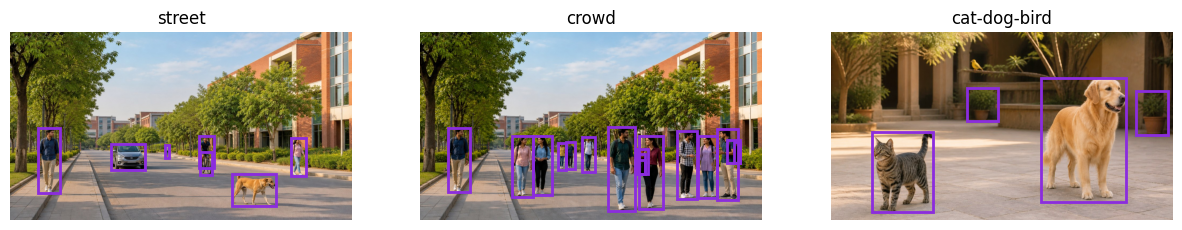

In [3]:
from ultralytics import YOLO
yolo = YOLO('yolov8n.pt')                      # downloads the weights the first time
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax_, name in zip(axes, ['street', 'crowd', 'cat-dog-bird']):
    r = yolo.predict(f'figures/{name}.jpg', imgsz=photo(name).size[::-1], conf=0.25, iou=0.7, verbose=False)[0]
    found = [yolo.names[int(c)] for c in r.boxes.cls]
    print(f'{name:13s}', {n: found.count(n) for n in sorted(set(found))})
    show(name, r.boxes.xyxy.tolist(), ax=ax_, title=name)

The cells, the parcel and the crack have no COCO class, so no detector here can find them. Their boxes are ours
(data/applications.json): the kind of list a detector for these classes would be trained on.

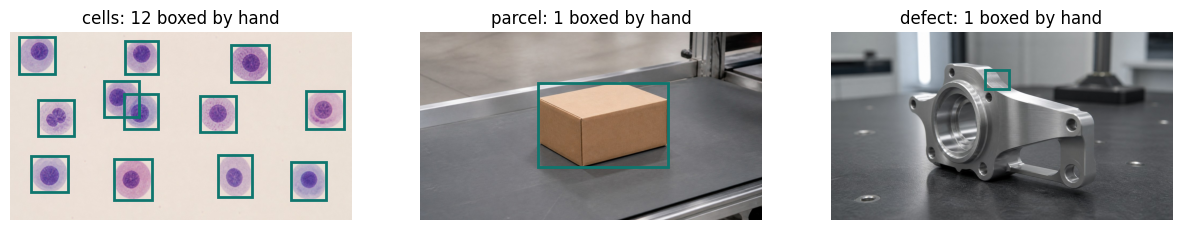

In [4]:
APPS = json.load(open('data/applications.json'))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax_, (name, lst) in zip(axes, APPS['photos'].items()):
    show(name, [b for _, b in lst], colors=['#0F766E'] * len(lst), ax=ax_, title=f'{name}: {len(lst)} boxed by hand')

The bird that YOLOv8n missed: its best bird box in the raw output, and why that box was dropped.

In [5]:
net = yolo.model.float().eval()
def raw_output(name):
    t = torch.from_numpy(np.array(photo(name))).permute(2, 0, 1)[None].float() / 255
    return net(t)[0][0].T                       # (cells, 84): c_x, c_y, w, h, then 80 class scores
out = raw_output('cat-dog-bird')
bird = 14                                       # "bird" in COCO's list of 80
is_bird = torch.where(out[:, 4:].argmax(1) == bird)[0]
k = int(is_bird[out[is_bird, 4 + bird].argmax()])
cx_, cy_, w_, h_ = out[k, :4].tolist()
best = [cx_ - w_ / 2, cy_ - h_ / 2, cx_ + w_ / 2, cy_ + h_ / 2]
gt_bird = [b for c, b in A['photos']['cat-dog-bird'] if c == 'bird'][0]
iou_bird = float(torchvision.ops.box_iou(torch.tensor([best]), torch.tensor([gt_bird], dtype=torch.float)))
second = out[k, 4:].topk(2)
print(f'best bird score {float(out[k, 4 + bird]):.3f} (cut-off 0.25) | IoU with our box {iou_bird:.3f} | '
      f'next guess: {yolo.names[int(second.indices[1])]} {float(second.values[1]):.3f}')
assert abs(float(out[k, 4 + bird]) - S['bird']['best']['score']) < 1e-3

best bird score 0.098 (cut-off 0.25) | IoU with our box 0.913 | next guess: banana 0.059


## Part 2 · From one label to a list

A classifier gives one label for the whole photo. ImageNet ResNet-50 on the courtyard photo:

In [6]:
from torchvision.models import resnet50, ResNet50_Weights
w = ResNet50_Weights.IMAGENET1K_V2
clf = resnet50(weights=w).eval()
p = clf(w.transforms()(photo('cat-dog'))[None]).softmax(-1)[0]
top = torch.topk(p, 5)
for v, i in zip(top.values, top.indices):
    print(f'{w.meta["categories"][i]:22s} {v:.3f}')
print('all 118 dog breeds together:', round(float(p[151:269].sum()), 3), '| the five cat classes:', round(float(p[281:286].sum()), 3))
assert abs(float(top.values[0]) - S['classifier']['top5'][0]['p']) < 2e-3

golden retriever       0.192
flat-coated retriever  0.015
tiger cat              0.013
Labrador retriever     0.012
tabby                  0.010
all 118 dog breeds together: 0.393 | the five cat classes: 0.03


A detector instead returns a list. YOLOv8n, with Ultralytics' own post-processing:

cat           0.921  box [115.5, 294.9, 321.3, 606.0]
potted plant  0.890  box [803.2, 139.2, 931.7, 325.1]
dog           0.889  box [406.9, 77.8, 768.7, 585.7]
potted plant  0.290  box [370.7, 253.3, 432.9, 316.6]


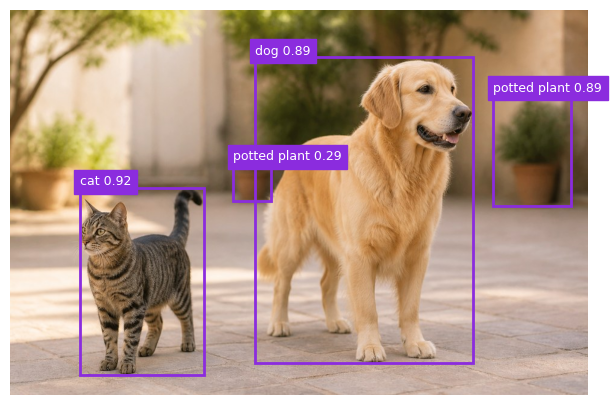

In [7]:
r = yolo.predict('figures/cat-dog.jpg', imgsz=(640, 960), conf=0.25, iou=0.7, verbose=False)[0]
for b, s, c in zip(r.boxes.xyxy, r.boxes.conf, r.boxes.cls):
    print(f'{yolo.names[int(c)]:13s} {float(s):.3f}  box {[round(v, 1) for v in b.tolist()]}')
show('cat-dog', r.boxes.xyxy.tolist(), [f'{yolo.names[int(c)]} {float(s):.2f}' for s, c in zip(r.boxes.conf, r.boxes.cls)]);

## Part 3 · Describe a box, compare two boxes

The dog's box in corner format, then as centre and size, then normalised:

In [8]:
dog = A['photos']['cat-dog'][0][1]; W, H = 960, 640
x1, y1, x2, y2 = dog
w, h = x2 - x1, y2 - y1
cx, cy = x1 + w / 2, y1 + h / 2
print('corners', dog, '| centre and size', (cx, cy, w, h))
print('normalised', [round(v, 3) for v in (cx / W, cy / H, w / W, h / H)])

corners [407, 83, 768, 588] | centre and size (587.5, 335.5, 361, 505)
normalised [0.612, 0.524, 0.376, 0.789]


The courtyard's label file in the YOLO format: one line per object, a COCO class index, then the normalised centre and size.

In [9]:
for name, b in A['photos']['cat-dog']:
    idx = [i for i, n in yolo.names.items() if n == name][0]
    print(idx, *[f'{v:.3f}' for v in ((b[0] + b[2]) / 2 / W, (b[1] + b[3]) / 2 / H, (b[2] - b[0]) / W, (b[3] - b[1]) / H)])

16 0.612 0.524 0.376 0.789
15 0.226 0.705 0.218 0.486


IoU by hand, for our box and a guess moved 60 px right and 40 px down:

In [10]:
guess = [x1 + 60, y1 + 40, x2 + 60, y2 + 40]
left, top = max(dog[0], guess[0]), max(dog[1], guess[1])
right, bottom = min(dog[2], guess[2]), min(dog[3], guess[3])
inter = max(0, right - left) * max(0, bottom - top)
area = lambda b: (b[2] - b[0]) * (b[3] - b[1])
union = area(dog) + area(guess) - inter
print(f'overlap ({left}, {top}, {right}, {bottom}) = {inter:,} px²;  union {union:,} px²;  IoU {inter / union:.3f}')
assert abs(inter / union - S['iou_practice']['iou']) < 1e-3

overlap (467, 123, 768, 588) = 139,965 px²;  union 224,645 px²;  IoU 0.623


In [11]:
def box_iou(a, b):              # a: (N, 4), b: (M, 4), corners
    lt = torch.max(a[:, None, :2], b[None, :, :2])  # overlap's top-left
    rb = torch.min(a[:, None, 2:], b[None, :, 2:])  # overlap's bottom-right
    inter = (rb - lt).clamp(min=0).prod(-1)         # (N, M); 0 if apart
    area = lambda x: (x[:, 2:] - x[:, :2]).prod(-1)
    return inter / (area(a)[:, None] + area(b)[None, :] - inter)

a, b = torch.tensor([dog], dtype=torch.float), torch.tensor([guess], dtype=torch.float)
print(box_iou(a, b), torchvision.ops.box_iou(a, b))

tensor([[0.6230]]) tensor([[0.6230]])


## Part 4 · One box is easy; several are not

The target a two-class localiser (cat, dog) learns for the single-cat photo, and for a patch of empty floor, where
"?" means the entry is left out of the loss:

In [12]:
cb = A['photos']['cat'][0][1]; Wc, Hc = photo('cat').size
y_cat = [1, (cb[0] + cb[2]) / 2 / Wc, (cb[1] + cb[3]) / 2 / Hc, (cb[2] - cb[0]) / Wc, (cb[3] - cb[1]) / Hc, 1, 0]
print('cat photo  :', [round(v, 3) for v in y_cat])
print('empty floor:', [0, '?', '?', '?', '?', '?', '?'])
assert [round(v, 3) for v in y_cat[1:5]] == S['single']['norm']

cat photo  : [1, 0.667, 0.527, 0.319, 0.642, 1, 0]
empty floor: [0, '?', '?', '?', '?', '?', '?']


The L1 box loss of the 60-px guess, in normalised units, and the average of the cat and dog boxes:

In [13]:
norm = lambda b, W, H: torch.tensor([(b[0] + b[2]) / 2 / W, (b[1] + b[3]) / 2 / H, (b[2] - b[0]) / W, (b[3] - b[1]) / H])
print('L1 =', round(float((norm(guess, W, H) - norm(dog, W, H)).abs().sum()), 3))
cat = A['photos']['cat-dog'][1][1]
avg = [(u + v) / 2 for u, v in zip(cat, dog)]
print('the average of the cat and dog boxes:', avg, '| IoU with dog', round(float(box_iou(torch.tensor([avg]), torch.tensor([dog], dtype=torch.float))), 3),
      '| IoU with cat', round(float(box_iou(torch.tensor([avg]), torch.tensor([cat], dtype=torch.float))), 3))

L1 = 0.125
the average of the cat and dog boxes: [259.5, 189.5, 544.5, 597.5] | IoU with dog 0.225 | IoU with cat 0.114


Two slots, two dogs: the same correct answer scored against the annotation list in two orders. The two slot boxes are DETR's real predictions (Appendix A recomputes them).

In [14]:
sl = S['slots']
slot1, slot2 = torch.tensor(sl['slot1']), torch.tensor(sl['slot2'])
left_dog, right_dog = torch.tensor(sl['left']), torch.tensor(sl['right'])
print('compared in list order (right dog listed first):', round(float((slot1 - right_dog).abs().sum() + (slot2 - left_dog).abs().sum()), 3))
print('compared the other way round:                   ', round(float((slot1 - left_dog).abs().sum() + (slot2 - right_dog).abs().sum()), 3))

compared in list order (right dog listed first): 1.212
compared the other way round:                    0.012


## Part 5 · A candidate at every place

The network's raw output, before any post-processing: one column per cell of three grids. For this 960 × 640 photo
that is 120 × 80 + 60 × 40 + 30 × 20 = 12,600 columns of 84 numbers: 4 box numbers (decoded to centre and size, in
pixels) and 80 class scores.

In [15]:
x = torch.from_numpy(np.array(photo('cat-dog'))).permute(2, 0, 1)[None].float() / 255
y, _ = net(x)
print(y.shape)                             # (1, 84, 12600)
raw = y[0].T                               # (12600, 84): one row per cell
off = 9600 + 2400                          # the stride-32 grid comes last
cell = lambda r, c: off + r * 30 + c
k = cell(10, 18)
ax, ay = (18 + .5) * 32, (10 + .5) * 32    # the cell's centre
bx, by, bw, bh = raw[k, :4].tolist()
box = [bx - bw / 2, by - bh / 2, bx + bw / 2, by + bh / 2]
ltrb = [ax - box[0], ay - box[1], box[2] - ax, box[3] - ay]
scores = raw[k, 4:]
print('cell (10, 18): centre', (ax, ay), '| dog score', round(float(scores[16]), 3), '| l, t, r, b =', [round(v, 1) for v in ltrb])
assert abs(float(scores[16]) - S['cell']['p_dog']) < 1e-3

torch.Size([1, 84, 12600])
cell (10, 18): centre (592.0, 336.0) | dog score 0.871 | l, t, r, b = [184.8, 260.4, 177.6, 252.1]


The one-cell rule (the cell that holds each box's centre), then the 3 × 3 block of centre sampling, and the targets of cell (10, 18):

In [16]:
cat = A['photos']['cat-dog'][1][1]
for name, b in [('dog', dog), ('cat', cat)]:
    mx, my = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
    print(f'{name}: centre ({mx}, {my}) is in cell ({int(my // 32)}, {int(mx // 32)})')
def centre_cells(b, s=32, radius=1.5):
    bx, by = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
    return [(r, c) for r in range(20) for c in range(30)
            if abs((c + .5) * s - bx) <= radius * s and abs((r + .5) * s - by) <= radius * s]
pos = {'dog': centre_cells(dog), 'cat': centre_cells(cat)}
print(pos)
target = [ax - dog[0], ay - dog[1], dog[2] - ax, dog[3] - ay]
print('box target', target)

dog: centre (587.5, 335.5) is in cell (10, 18)
cat: centre (216.5, 451.5) is in cell (14, 6)
{'dog': [(9, 17), (9, 18), (9, 19), (10, 17), (10, 18), (10, 19), (11, 17), (11, 18), (11, 19)], 'cat': [(13, 5), (13, 6), (13, 7), (14, 5), (14, 6), (14, 7), (15, 5), (15, 6), (15, 7)]}
box target [185.0, 253.0, 176.0, 252.0]


The loss at that cell: binary cross-entropy for each of the 80 classes, and L1 on the four distances.

In [17]:
yc = torch.zeros(80); yc[16] = 1.0
bce = F.binary_cross_entropy(scores.clamp(1e-7, 1 - 1e-7), yc, reduction='none')
print('dog term', round(float(bce[16]), 3), '| other 79 together', round(float(bce.sum() - bce[16]), 4), '| class loss', round(float(bce.sum()), 3))
l1 = [abs(p - t) for p, t in zip(ltrb, target)]
print('box L1 terms', [round(v, 1) for v in l1], 'sum', round(sum(l1), 1), 'px')
assert abs(float(bce[16]) - S['cell']['bce_dog']) < 1e-3 and abs(sum(l1) - S['cell']['l1']) < 0.1

dog term 0.139 | other 79 together 0.0004 | class loss 0.139
box L1 terms [0.2, 7.4, 1.6, 0.1] sum 9.3 px


The same loss over the whole 30 × 20 grid, with targets built from the annotation:

In [18]:
s32 = raw[off:, 4:].clamp(1e-7, 1 - 1e-7)           # (600, 80) class scores
d32 = raw[off:, :4]
Y = torch.zeros(600, 80); dist_t = torch.zeros(600, 4); idx = []
centres = torch.tensor([((c + .5) * 32, (r + .5) * 32) for r in range(20) for c in range(30)])
for name, label, b in [('dog', 16, dog), ('cat', 15, cat)]:
    for r, c in pos[name]:
        i = r * 30 + c; idx.append(i); Y[i, label] = 1
        cx_, cy_ = centres[i]
        dist_t[i] = torch.tensor([cx_ - b[0], cy_ - b[1], b[2] - cx_, b[3] - cy_])
idx = torch.tensor(idx)
pred_box = torch.cat([d32[:, :2] - d32[:, 2:] / 2, d32[:, :2] + d32[:, 2:] / 2], 1)
dist = torch.cat([centres - pred_box[:, :2], pred_box[:, 2:] - centres], 1)
cls_loss = F.binary_cross_entropy(s32, Y, reduction='sum')
box_loss = (dist[idx] - dist_t[idx]).abs().sum() / 32   # in cells
print(f'{len(idx)} positives | class loss {cls_loss:.3f} | box loss {box_loss:.3f} cells | per positive {(cls_loss + box_loss) / len(idx):.3f}')

18 positives | class loss 102.877 | box loss 5.034 cells | per positive 5.995


The total is large, and that is a lesson rather than a bug. YOLOv8 was not trained with our 3 × 3 rule: its own
assigner picked a slightly different block of cells, so cells it learned to fire at count as background here, and
cells in our block that it learned to leave quiet count as missed positives. The potted plants fire too, and our
annotation does not list them. A loss is only meaningful against the targets the network was trained to meet.

Decode every cell and keep the confident ones:

31 of 12600 cells have a score ≥ 0.25: {'cat': 10, 'dog': 10, 'potted plant': 11}


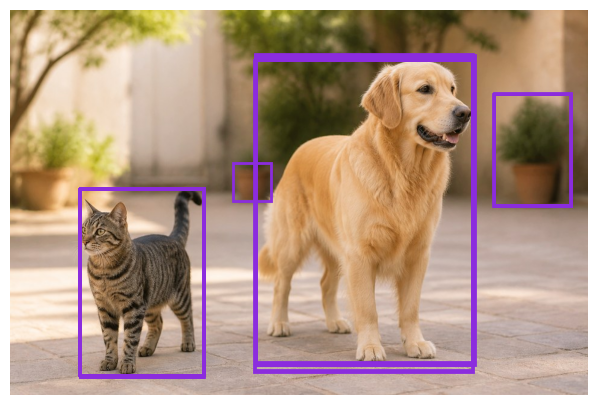

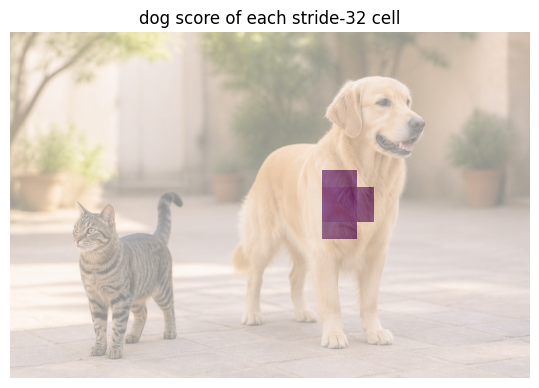

In [19]:
score, label = raw[:, 4:].max(1)
keep = score >= 0.25
print(int(keep.sum()), 'of', raw.shape[0], 'cells have a score ≥ 0.25:', {yolo.names[int(c)]: int((label[keep] == c).sum()) for c in label[keep].unique()})
xyxy = torch.cat([raw[:, :2] - raw[:, 2:4] / 2, raw[:, :2] + raw[:, 2:4] / 2], 1)
show('cat-dog', xyxy[keep].tolist());
plt.figure(figsize=(7, 4.5)); plt.imshow(photo('cat-dog')); plt.imshow(raw[off:, 4 + 16].reshape(20, 30), alpha=.55, extent=(0, 960, 640, 0), cmap='Purples'); plt.title('dog score of each stride-32 cell'); plt.axis('off');

## Part 6 · One box per object: non-maximum suppression

In [20]:
def nms(boxes, scores, thr=0.7):
    order = scores.argsort(descending=True)          # step 1
    keep = []
    while order.numel() > 0:
        i = order[0]; keep.append(i)                 # step 2
        ious = box_iou(boxes[i, None], boxes[order[1:]])[0]
        order = order[1:][ious <= thr]               # step 3, then repeat
    return torch.stack(keep)

b, s, l = xyxy[keep], score[keep], label[keep]
ours = nms(b + l[:, None] * 4096, s)          # offset each class so classes never overlap: class-aware
theirs = torchvision.ops.batched_nms(b, s, l, 0.7)
print('ours', ours.tolist(), '| torchvision', theirs.tolist())
for i in ours: print(f'{yolo.names[int(l[i])]:13s} {float(s[i]):.3f}')
assert sorted(ours.tolist()) == sorted(theirs.tolist())

ours [24, 6, 14, 0] | torchvision [24, 6, 14, 0]
cat           0.921
potted plant  0.890
dog           0.889
potted plant  0.290


The dog's ten boxes against the one NMS keeps:

In [21]:
d = (l == 16)
db, ds = b[d], s[d]
top = int(ds.argmax())
print([round(float(v), 3) for v in box_iou(db[top, None], db)[0]])

[0.962, 0.956, 0.994, 1.0, 0.995, 0.987, 0.985, 0.98, 0.977, 0.98]


The IoU threshold on the crowd photo, class-aware against class-agnostic NMS on the street photo, and two dogs of one class:

In [22]:
def candidates(name, conf=0.25):
    out = raw_output(name)
    sc, lb = out[:, 4:].max(1)
    k = sc >= conf
    bx = torch.cat([out[:, :2] - out[:, 2:4] / 2, out[:, :2] + out[:, 2:4] / 2], 1)
    return bx[k], sc[k], lb[k]
cb_, cs, cl = candidates('crowd'); p_ = cl == 0
for thr in (0.0, 0.3, 0.5, 0.7, 0.9, 0.95):
    print(f'threshold {thr}: {len(nms(cb_[p_], cs[p_], thr))} people kept from {int(p_.sum())} candidates')
sb, ss, sl_ = candidates('street')
aware = torchvision.ops.batched_nms(sb, ss, sl_, 0.3)
agnostic = torchvision.ops.nms(sb, ss, 0.3)
print('class-aware keeps', sorted(yolo.names[int(c)] for c in sl_[aware]))
print('class-agnostic keeps', sorted(yolo.names[int(c)] for c in sl_[agnostic]))
tb, ts, tl = candidates('two-dogs'); dg = tl == 16
kept_dogs = nms(tb[dg], ts[dg])
print(int(dg.sum()), 'dog boxes ->', len(kept_dogs), 'kept; IoU between the two kept boxes:',
      round(float(box_iou(tb[dg][kept_dogs[:1]], tb[dg][kept_dogs[1:2]])), 3))
assert int(dg.sum()) == S['nms_two_dogs']['n'] and len(kept_dogs) == 2

threshold 0.0: 9 people kept from 112 candidates
threshold 0.3: 11 people kept from 112 candidates
threshold 0.5: 11 people kept from 112 candidates
threshold 0.7: 11 people kept from 112 candidates
threshold 0.9: 11 people kept from 112 candidates
threshold 0.95: 13 people kept from 112 candidates
class-aware keeps ['bicycle', 'car', 'dog', 'person', 'person', 'person', 'person']
class-agnostic keeps ['car', 'dog', 'person', 'person', 'person', 'person']


20 dog boxes -> 2 kept; IoU between the two kept boxes: 0.0


The whole detector at test time, as on the slide:

In [23]:
from torchvision.ops import box_convert, batched_nms
def detect(img, net, names, score_thr=0.25, iou_thr=0.7):
    y, _ = net(img)                                        # (1, 84, cells): always this shape
    boxes = box_convert(y[0, :4].T, 'cxcywh', 'xyxy')      # (cells, 4), in pixels
    scores, labels = y[0, 4:].max(0)                       # each cell's best class and score
    keep = scores >= score_thr
    boxes, scores, labels = boxes[keep], scores[keep], labels[keep]
    keep = batched_nms(boxes, scores, labels, iou_thr)
    return [(names[int(c)], round(float(s), 3), [round(v, 1) for v in bb.tolist()]) for bb, s, c in zip(boxes[keep], scores[keep], labels[keep])]
for det in detect(x, net, yolo.names): print(det)

('cat', 0.921, [115.5, 294.9, 321.3, 606.0])
('potted plant', 0.89, [803.2, 139.2, 931.7, 325.1])
('dog', 0.889, [406.9, 77.8, 768.7, 585.7])
('potted plant', 0.29, [370.7, 253.3, 432.9, 316.6])


## Part 7 · Three grids for three sizes

Which grid produced each kept detection on the street photo with the bus?

In [24]:
im = photo('scale'); Wp, Hp = im.size
out = raw_output('scale')
sizes = [(Hp // s) * (Wp // s) for s in (8, 16, 32)]
print('cells per grid', sizes, '=', sum(sizes))
sc, lb = out[:, 4:].max(1); k = torch.where(sc >= 0.25)[0]
bx = torch.cat([out[:, :2] - out[:, 2:4] / 2, out[:, :2] + out[:, 2:4] / 2], 1)
kept = k[torchvision.ops.batched_nms(bx[k], sc[k], lb[k], 0.7)]
stride = lambda i: 8 if i < sizes[0] else 16 if i < sizes[0] + sizes[1] else 32
for i in kept: print(f'{yolo.names[int(lb[i])]:8s} {float(sc[i]):.3f}  from the {stride(int(i))}-px grid')

cells per grid [14080, 3520, 880] = 18480
bus      0.930  from the 32-px grid
person   0.848  from the 16-px grid
person   0.681  from the 8-px grid
bicycle  0.587  from the 16-px grid


## Part 8 · Measuring a detector

Greedy evaluation matching for one class, then precision, recall and average precision.

In [25]:
def evaluate(dets, gts, thr=0.5):
    """dets: (photo, score, box); gts: (photo, box). Returns hit flags in score order."""
    claimed, hits = set(), []
    for ph, sc, bx in sorted(dets, key=lambda d: -d[1]):
        cands = [(float(box_iou(torch.tensor([bx]), torch.tensor([g], dtype=torch.float))), i) for i, (gp, g) in enumerate(gts) if gp == ph and i not in claimed]
        best = max(cands, default=(0, None))
        hits.append(best[0] >= thr)
        if hits[-1]: claimed.add(best[1])
    return hits

def average_precision(hits, n_gt):
    tp = np.cumsum(hits); fp = np.cumsum([not h for h in hits])
    prec, rec = tp / (tp + fp), tp / n_gt
    env = np.maximum.accumulate(prec[::-1])[::-1]       # best precision at this recall or beyond
    return float(np.sum(np.diff(np.concatenate([[0], rec])) * env)), prec, rec

hits = [True, True, False, False, True, False]          # the slide's small practice list
ap, prec, rec = average_precision(hits, 3)
print('precision', np.round(prec, 3), '| recall', np.round(rec, 3), '| AP', round(ap, 3))
assert abs(ap - S['practice']['ap']) < 1e-3

precision [          1           1       0.667         0.5         0.6         0.5] | recall [      0.333       0.667       0.667       0.667           1           1] | AP 0.867


Part 1's bird: true positives, false positives and misses on the camera-trap photo at two score cut-offs.

In [26]:
def yolo_dets(name):
    rr = yolo.predict(f'figures/{name}.jpg', imgsz=photo(name).size[::-1], conf=0.01, iou=0.7, verbose=False)[0]
    return [(name, yolo.names[int(c)], float(s), b.tolist()) for b, s, c in zip(rr.boxes.xyxy, rr.boxes.conf, rr.boxes.cls)]
def counts(name, conf):
    dets = [d for d in yolo_dets(name) if d[2] >= conf]
    tp = fp = fn = 0
    for cls in A['classes']:
        gts = [(name, bb) for c, bb in A['photos'][name] if c == cls]
        hits_ = evaluate([(ph, sc, bx) for ph, c, sc, bx in dets if c == cls], gts)
        tp += sum(hits_); fp += len(hits_) - sum(hits_); fn += len(gts) - sum(hits_)
    return tp, fp, fn
for conf in (0.25, 0.05):
    print(f'score >= {conf}: TP, FP, FN =', counts('cat-dog-bird', conf))

score >= 0.25: TP, FP, FN = (2, 0, 1)


score >= 0.05: TP, FP, FN = (3, 0, 0)


YOLOv8n on our eight photos (7 classes), at IoU 0.5 and averaged over IoU 0.5 to 0.95:

In [27]:
def benchmark(fn):
    dets = [d for n in A['photos'] for d in fn(n)]
    ap50, apall = [], []
    for cls in A['classes']:
        gts = [(n, bb) for n, lst in A['photos'].items() for c, bb in lst if c == cls]
        ds = [(ph, sc, bx) for ph, c, sc, bx in dets if c == cls]
        per = [average_precision(evaluate(ds, gts, t), len(gts))[0] if ds else 0 for t in np.arange(.5, .96, .05)]
        ap50.append(per[0]); apall.append(np.mean(per))
    return np.mean(ap50), np.mean(apall)
print('YOLOv8n  mAP@0.5 = %.3f   AP@[.5:.95] = %.3f' % benchmark(yolo_dets))

YOLOv8n  mAP@0.5 = 1.000   AP@[.5:.95] = 0.936


These numbers come from the notebook's own small evaluator (all-point interpolation); the slides use COCO's
101-point version, so the third decimal can differ. Eight clean photos are not a benchmark: on COCO's 5,000
validation photos the published AP of YOLOv8n is 37.3.

## Appendix A · DETR: a fixed set of slots, matched to objects

DETR on the courtyard photo: 100 queries, each a class (91 COCO ids or "no object") and a normalised box.

In [28]:
from transformers import DetrImageProcessor, DetrForObjectDetection
proc = DetrImageProcessor.from_pretrained('facebook/detr-resnet-50')
detr = DetrForObjectDetection.from_pretrained('facebook/detr-resnet-50', attn_implementation='eager').eval()
out = detr(**proc(images=photo('cat-dog'), return_tensors='pt'), output_attentions=True)
prob = out.logits.softmax(-1)[0]                 # (100, 92); the last column is "no object"
print('queries saying "no object" with p > 0.9:', int((prob[:, -1] > 0.9).sum()))
for q in torch.argsort(prob[:, -1])[:6].tolist():
    c = int(prob[q, :-1].argmax())
    print(f'query {q:2d}: {detr.config.id2label[c]:12s} p = {float(prob[q, c]):.3f}  box (cx, cy, w, h) = {[round(v, 3) for v in out.pred_boxes[0, q].tolist()]}')

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

DetrForObjectDetection LOAD REPORT from: facebook/detr-resnet-50
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
model.backbone.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer1.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


queries saying "no object" with p > 0.9: 88
query 71: dog          p = 0.999  box (cx, cy, w, h) = [0.615, 0.526, 0.377, 0.787]
query 61: cat          p = 0.999  box (cx, cy, w, h) = [0.224, 0.706, 0.216, 0.483]
query 12: potted plant p = 0.998  box (cx, cy, w, h) = [0.904, 0.364, 0.139, 0.287]
query 81: potted plant p = 0.989  box (cx, cy, w, h) = [0.424, 0.419, 0.08, 0.15]
query 48: potted plant p = 0.973  box (cx, cy, w, h) = [0.082, 0.389, 0.163, 0.269]
query 15: potted plant p = 0.843  box (cx, cy, w, h) = [0.162, 0.262, 0.326, 0.522]


Where query 71 (the dog) looked: its cross-attention in the last decoder layer, averaged over the 8 heads.

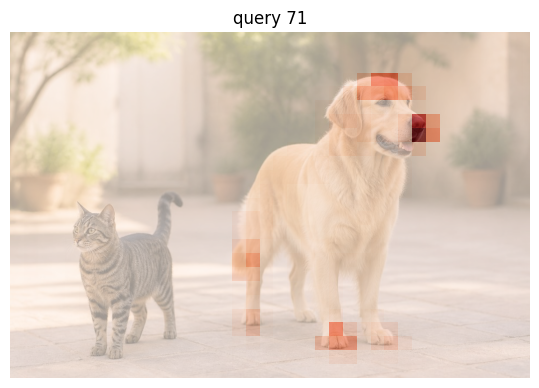

In [29]:
att = out.cross_attentions[-1][0].mean(0)        # (100, 950): 25 x 38 image tokens
plt.figure(figsize=(7, 4.5)); plt.imshow(photo('cat-dog'))
plt.imshow(att[71].reshape(25, 38), extent=(0, 38 * 32 / 1.25, 25 * 32 / 1.25, 0), alpha=.6, cmap='Reds'); plt.xlim(0, 960); plt.ylim(640, 0); plt.axis('off'); plt.title('query 71');

Matching, as DETR's training does it: the cost of every (target, query) pair, then the cheapest one-to-one pairing.

In [30]:
def cxcywh_to_xyxy(b): return torch.cat([b[..., :2] - b[..., 2:] / 2, b[..., :2] + b[..., 2:] / 2], -1)
out2 = detr(**proc(images=photo('two-dogs'), return_tensors='pt'))
p2, b2 = out2.logits.softmax(-1)[0], out2.pred_boxes[0]
Q = S['match']['queries']                         # four of the 100 queries, as on the slide
gt = torch.tensor(S['match']['target_boxes'])     # left dog, right dog, normalised (cx, cy, w, h)
dog_id = 18                                       # "dog" in DETR's labels
cost = (-p2[Q][:, dog_id][None, :]
        + 5 * torch.cdist(gt, b2[Q], p=1)
        - 2 * torchvision.ops.generalized_box_iou(cxcywh_to_xyxy(gt), cxcywh_to_xyxy(b2[Q])))
print(np.round(cost.numpy(), 2))
from scipy.optimize import linear_sum_assignment
rows, cols = linear_sum_assignment(cost.numpy())
print('left dog -> query', Q[cols[0]], '| right dog -> query', Q[cols[1]])
brute = min(itertools.permutations(range(len(Q)), 2), key=lambda pr: float(cost[0, pr[0]] + cost[1, pr[1]]))
assert list(cols) == list(brute)

[[      -2.95        3.09        6.07       -1.71]
 [       3.08        -2.9        4.47        4.26]]
left dog -> query 61 | right dog -> query 98


Greedy can lose; the Hungarian algorithm finds the best total:

In [31]:
T = np.array([[1, 2], [2, 9]])
print('greedy: left dog takes q1 (1), right dog gets q2 (9): total 10')
print('best:', linear_sum_assignment(T), 'total', T[0, 1] + T[1, 0])

greedy: left dog takes q1 (1), right dog gets q2 (9): total 10
best: (array([0, 1]), array([1, 0])) total 4


DETR on the same eight photos, with the evaluator of Part 8:

In [32]:
def detr_dets(name):
    im = photo(name)
    o = detr(**proc(images=im, return_tensors='pt'))
    res = proc.post_process_object_detection(o, threshold=0.01, target_sizes=[im.size[::-1]])[0]
    return [(name, detr.config.id2label[int(c)], float(s), bb.tolist()) for bb, s, c in zip(res['boxes'], res['scores'], res['labels'])]
print('DETR     mAP@0.5 = %.3f   AP@[.5:.95] = %.3f' % benchmark(detr_dets))

DETR     mAP@0.5 = 1.000   AP@[.5:.95] = 0.882


On COCO's 5,000 validation photos the published numbers are 37.3 (YOLOv8n) and 42.0 (DETR-R50).